# Линейна регресия

- [Simple Regression](https://www.desmos.com/calculator/askfgexkaa)

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from io import StringIO

sns.set_theme(style="whitegrid", context="notebook")

# Borjas, Labor Economics, Table 1-1: Characteristics of Occupations, 2001 (CPS)
csv = """occupation,log_wage,schooling,female_share
"Administrators and officials, public administration",3.24,15.7,52.4\n"Other executives, administrators, and managers",3.29,14.9,42.0\nManagement-related occupations,3.16,15.4,59.4\nEngineers,3.37,15.8,10.7\nMathematical and computer scientists,3.36,15.6,32.2\nNatural scientists,3.22,17.4,34.2\nHealth diagnosing occupations,3.91,19.8,31.2\nHealth assessment and treating occupations,3.23,16.2,86.2\n"Teachers, college and university",3.17,18.8,44.7\n"Teachers, except college and university",2.92,16.5,75.8\nLawyers and judges,3.72,19.7,29.3\nOther professional specialty occupations,2.90,15.9,54.0\nHealth technologists and technicians,2.76,14.2,83.1\nEngineering and science technicians,2.97,13.8,26.0\n"Technicians, except health, engineering, and science",3.30,15.4,48.5\n"Supervisors and proprietors, sales occupations",2.96,13.9,37.6\n"Sales representatives, finance and business services",3.39,15.1,44.7\n"Sales representatives, commodities, except retail",3.14,14.4,25.4\n"Sales workers, retail and personal services",2.61,13.4,64.0\nSales-related occupations,2.93,14.8,72.4\n"Supervisors, administrative support",2.94,13.8,61.2\nComputer equipment operators,2.91,13.8,57.1\n"Secretaries, stenographers, and typists",2.75,13.8,98.0\n"Financial records, processing occupations",2.67,14.2,92.9\nMail and message distributing,2.87,13.2,41.9\n"Other administrative support occupations, including clerical",2.66,13.4,79.2\nPrivate household service occupations,2.46,10.6,96.0\nProtective service occupations,2.80,13.6,18.7\nFood service occupations,2.23,11.4,60.0\nHealth service occupations,2.38,13.2,89.1\nCleaning and building service occupations,2.37,11.2,48.2\nPersonal service occupations,2.55,13.4,80.4\nMechanics and repairers,2.81,12.6,5.2\nConstruction trades,2.74,11.9,2.4\nOther precision production occupations,2.82,12.3,22.5\n"Machine operators and tenders, except precision",2.62,11.8,35.2\n"Fabricators, assemblers, inspectors, and samplers",2.65,12.0,36.2\nMotor vehicle operators,2.59,12.1,12.7\nOther transportation occupations and material moving,2.68,11.8,6.3\nConstruction laborer,2.44,10.5,3.9\n"Freight, stock, and material handlers",2.44,12.0,30.4\n"Other handlers, equipment cleaners, and laborers",2.42,11.3,28.0\nFarm operators and managers,2.52,12.9,20.5\nFarm workers and related occupations,2.29,9.9,18.5\nForestry and fishing occupations,2.70,12.0,3.7
"""

df = pd.read_csv(StringIO(csv))
df["schooling_over_16y"] = (df["schooling"] > 16).astype(int)
df.head(10)

,occupation,log_wage,schooling,female_share,schooling_over_16y
0,"Administrators and officials, public administr...",3.24,15.7,52.4,0
1,"Other executives, administrators, and managers",3.29,14.9,42.0,0
2,Management-related occupations,3.16,15.4,59.4,0
3,Engineers,3.37,15.8,10.7,0
4,Mathematical and computer scientists,3.36,15.6,32.2,0
5,Natural scientists,3.22,17.4,34.2,1
6,Health diagnosing occupations,3.91,19.8,31.2,1
7,Health assessment and treating occupations,3.23,16.2,86.2,1
8,"Teachers, college and university",3.17,18.8,44.7,1
9,"Teachers, except college and university",2.92,16.5,75.8,1


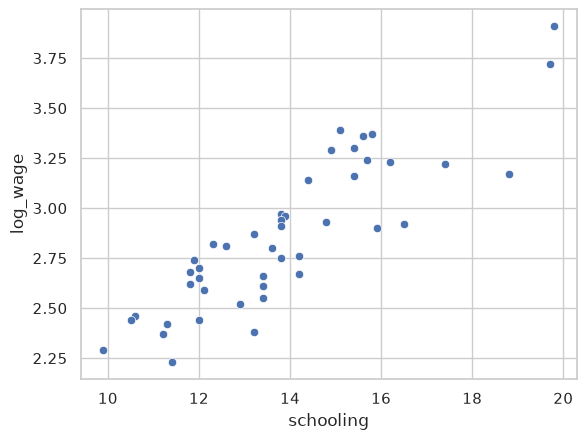

In [4]:
sns.scatterplot(data=df, x="schooling", y="log_wage")
plt.show()

In [5]:
model = smf.ols("log_wage ~ schooling", data=df).fit()
print(model.params.round(3))

Intercept    0.869
schooling    0.143
dtype: float64


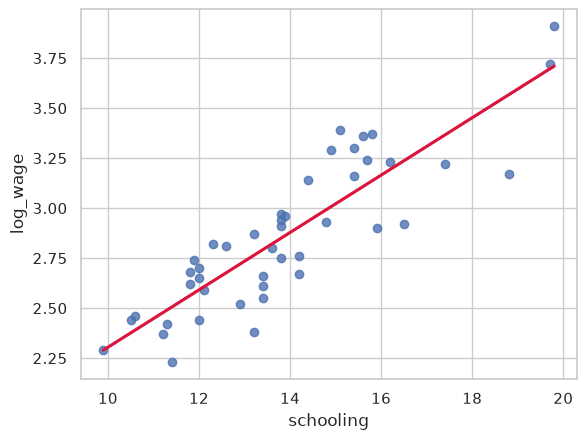

In [6]:
sns.regplot(data=df, x="schooling", y="log_wage", ci=None, line_kws={"color": "crimson"})
plt.show()

In [7]:
model = smf.ols("log_wage ~ schooling", data=df).fit()
print(model.params.round(3))

Intercept    0.869
schooling    0.143
dtype: float64


## Confounding


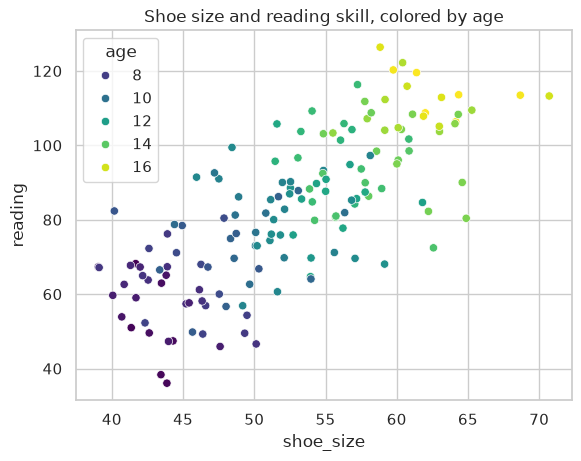

In [8]:
rng = np.random.default_rng(42)
n = 150

shoe_df = pd.DataFrame({
    "age": rng.uniform(6, 17, n),
})

shoe_df["shoe_size"] = 30 + 2.0 * shoe_df["age"] + rng.normal(0, 3, n)
shoe_df["reading"] = 20 + 5.5 * shoe_df["age"] + rng.normal(0, 10, n)

sns.scatterplot(
    data=shoe_df,
    x="shoe_size",
    y="reading",
    hue="age",
    palette="viridis",
)
plt.title("Shoe size and reading skill, colored by age")
plt.show()

unadjusted = smf.ols("reading ~ shoe_size", data=shoe_df).fit()
adjusted = smf.ols("reading ~ shoe_size + age", data=shoe_df).fit()

In [9]:
unadjusted = smf.ols("reading ~ shoe_size", data=shoe_df).fit()
print(unadjusted.params.round(3))

Intercept   -28.787
shoe_size     2.113
dtype: float64


In [10]:
adjusted = smf.ols("reading ~ shoe_size + age", data=shoe_df).fit()
print(adjusted.params.round(3))

Intercept    36.045
shoe_size    -0.680
age           7.249
dtype: float64
